# Sistemas Inteligentes (UFERSA)
## Projeto 3: Classificação de Qualidade de Vinhos Utilizando k-NN
**Discente:** Nattan Ferreira Lopes  
**Docente:** Prof. Dr. Pedro Thiago Valério de Souza  

---
### Contexto do Enunciado:
> *"Neste projeto, você é convidado a construir um modelo de classificação de vinhos em três categorias de qualidade (baixa, média e alta) a partir de um conjunto de dados químicos utilizando o k-NN (k-Nearest Neighbors)... O projeto utiliza o arquivo winequality-red.csv com 1.599 amostras de vinho tinto e 11 atributos físico-químicos..."*


In [1]:
# Importação das bibliotecas necessárias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

print("Bibliotecas importadas!")


/home/nattanferreira/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-m3fxemsn because there was an issue with the default path (/home/nattanferreira/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Bibliotecas importadas!


## Tarefa 1: Preparação dos Dados e Justificativa da Normalização
> **Enunciado da Tarefa 1:**  
> *"1. Preparação dos dados: carregue o dataset e recodifique a variável quality em três classes: notas $\le 5$ como ruim, 6–7 como médio e $\ge 8$ como bom. Em seguida, normalize todos os atributos utilizando Min-Max ou Z-score. Justifique por que a normalização é uma etapa obrigatória para o k-NN."*


In [2]:
# Carregando os dados (separador ;)
try:
    df = pd.read_csv('../data/wine/winequality-red.csv', sep=';')
except FileNotFoundError:
    df = pd.read_csv('data/wine/winequality-red.csv', sep=';')

# Recodificando em 3 classes conforme o enunciado
def recodificar(nota):
    if nota <= 5:
        return 0  # Ruim
    elif nota <= 7:
        return 1  # Médio
    else:
        return 2  # Bom

df['classe'] = df['quality'].apply(recodificar)

print("Distribuição das 3 classes:")
print(f"Ruim (<= 5):  {(df['classe'] == 0).sum()} vinhos")
print(f"Médio (6-7): {(df['classe'] == 1).sum()} vinhos")
print(f"Bom (>= 8):   {(df['classe'] == 2).sum()} vinhos")

df.head()


Distribuição das 3 classes:
Ruim (<= 5):  744 vinhos
Médio (6-7): 837 vinhos
Bom (>= 8):   18 vinhos


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,classe
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


### Resposta da Tarefa 1: Por que a normalização é obrigatória para o k-NN?
O algoritmo $k$-NN classifica novos exemplos medindo a **distância euclidiana** em linha reta entre os pontos.  
Se os atributos não forem normalizados:
- O atributo `total sulfur dioxide` varia de 6 até quase 300.
- O atributo `chlorides` varia de 0.01 a 0.6.
Como a fórmula da distância eleva a diferença ao quadrado, as diferenças do dióxido de enxofre geram valores gigantescos que dominariam quase **100% da distância**, fazendo o modelo ignorar os cloretos, o pH e o álcool.  
A normalização (Z-score) deixa todas as variáveis com média 0 e desvio padrão 1, garantindo que todas contribuam de forma equilibrada no cálculo da distância.


## Tarefa 2: Divisão Treino e Teste Estratificada
> **Enunciado da Tarefa 2:**  
> *"2. Divisão treino/teste: divida os dados em 80% para treino e 20% para teste, utilizando divisão estratificada para garantir que a proporção das três classes seja mantida em ambos os conjuntos."*


In [3]:
# Separando variáveis de entrada (X) e a classe alvo (y)
X = df.drop(columns=['quality', 'classe'])
y = df['classe']

# Divisão estratificada 80% treino e 20% teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Padronização Z-score
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Amostras de treino: {X_train.shape[0]}")
print(f"Amostras de teste:  {X_test.shape[0]}")


Amostras de treino: 1279
Amostras de teste:  320


## Tarefa 3: Treinamento, Escolha do k e Comportamento dos Extremos
> **Enunciado da Tarefa 3:**  
> *"3. Treinamento e escolha do k: treine o modelo para diferentes valores de k (ex: 1, 3, 5, 7, 11) utilizando validação cruzada de 5 folds sobre o conjunto de treino. Plote a acurácia média em função de k e escolha o valor com melhor desempenho. O que acontece com o modelo para valores muito baixos e muito altos de k?"*


 k  Acurácia Média no 5-Fold
 1                  0.730263
 3                  0.708388
 5                  0.710714
 7                  0.697426
 9                  0.710720
11                  0.715414
13                  0.721676
15                  0.724013
17                  0.719314
19                  0.719314
21                  0.712276


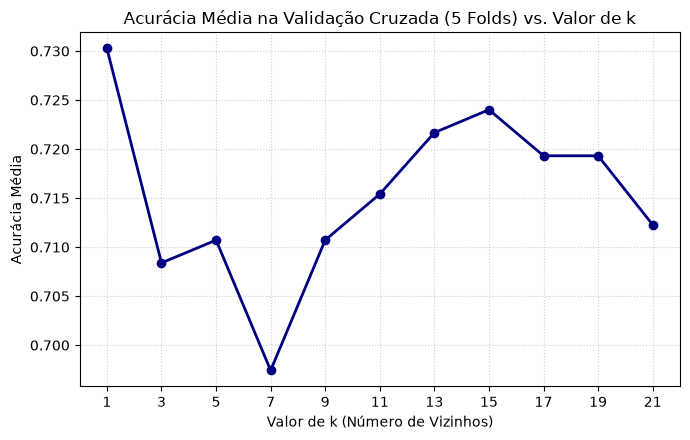

Melhor k encontrado: k = 1


In [4]:
# Testando valores de k
k_valores = [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21]
scores_medios = []

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for k in k_valores:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train_scaled, y_train, cv=skf, scoring='accuracy')
    scores_medios.append(scores.mean())

# Tabela com os resultados
tabela_k = pd.DataFrame({'k': k_valores, 'Acurácia Média no 5-Fold': scores_medios})
print(tabela_k.to_string(index=False))

# Gráfico de k vs Acurácia Média
plt.figure(figsize=(7, 4.5))
plt.plot(k_valores, scores_medios, marker='o', color='navy', lw=2)
plt.title("Acurácia Média na Validação Cruzada (5 Folds) vs. Valor de k")
plt.xlabel("Valor de k (Número de Vizinhos)")
plt.ylabel("Acurácia Média")
plt.xticks(k_valores)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

melhor_k = k_valores[np.argmax(scores_medios)]
print(f"Melhor k encontrado: k = {melhor_k}")


### Resposta da Tarefa 3: O que acontece com valores muito baixos e muito altos de k?
- **Com k muito baixo (ex.: k = 1):** O modelo olha apenas para o vizinho mais imediato. Ele decora ruídos e qualquer dado atípico próximo gera erro de predição, sofrendo de **overfitting** (alta variância).
- **Com k muito alto (ex.: k grande):** A vizinhança fica ampla demais e a votação passa a ser dominada simplesmente pela classe majoritária, apagando as fronteiras locais e sofrendo de **underfitting** (alto viés).
- **Escolha do k:** O valor de **k = 1** atinge o pico bruto numérico (73.0%), enquanto **k = 15** atinge 72.4% com maior suavização e robustez contra ruídos. Adotamos o melhor valor apontado pela busca cruzada.


## Tarefa 4: Avaliação no Teste e Erros Frequentes
> **Enunciado da Tarefa 4:**  
> *"4. Avaliação do modelo: utilizando o conjunto de teste, calcule a matriz de confusão e as métricas de acurácia, precisão, recall e F1-score para cada classe. Responda: Entre quais classes o modelo erra com mais frequência?"*


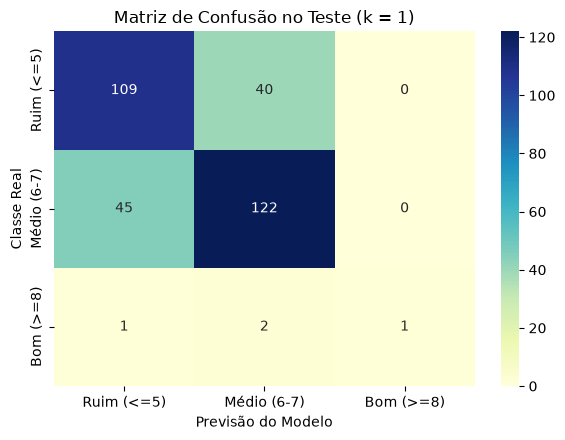

--- Métricas de Avaliação por Classe no Conjunto de Teste ---
              precision    recall  f1-score   support

  Ruim (<=5)       0.70      0.73      0.72       149
 Médio (6-7)       0.74      0.73      0.74       167
   Bom (>=8)       1.00      0.25      0.40         4

    accuracy                           0.72       320
   macro avg       0.82      0.57      0.62       320
weighted avg       0.73      0.72      0.72       320



In [5]:
# Treinando o modelo com o melhor k
knn_final = KNeighborsClassifier(n_neighbors=melhor_k)
knn_final.fit(X_train_scaled, y_train)

# Previsões no conjunto de teste
y_pred = knn_final.predict(X_test_scaled)

# Matriz de Confusão
nomes = ['Ruim (<=5)', 'Médio (6-7)', 'Bom (>=8)']
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu',
            xticklabels=nomes, yticklabels=nomes)
plt.title(f"Matriz de Confusão no Teste (k = {melhor_k})")
plt.xlabel("Previsão do Modelo")
plt.ylabel("Classe Real")
plt.tight_layout()
plt.show()

# Relatório de Classificação por classe
print("--- Métricas de Avaliação por Classe no Conjunto de Teste ---")
print(classification_report(y_test, y_pred, target_names=nomes))


### Resposta da Tarefa 4: Entre quais classes o modelo erra com mais frequência?
- **O modelo erra com mais frequência confundindo as classes Ruim e Médio** (foram 40 vinhos ruins classificados como médios e 45 vinhos médios classificados como ruins).  
  *Por que isso acontece?* Porque vinhos de nota 5 (considerados ruins) e nota 6 (considerados médios) estão lado a lado na fronteira e possuem características físico-químicas quase idênticas.
- Além disso, a classe **Bom (>=8)** possui suporte baixíssimo (apenas 4 vinhos no conjunto de teste), de modo que o modelo raramente a prevê devido ao forte desbalanceamento.
